# Fetching the Dataset

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

In [ ]:
! gdown 1frbMGA74X5EYZJHeCDIC3O1eijzvQIsX

Downloading...
From (original): https://drive.google.com/uc?id=1frbMGA74X5EYZJHeCDIC3O1eijzvQIsX
From (redirected): https://drive.google.com/uc?id=1frbMGA74X5EYZJHeCDIC3O1eijzvQIsX&confirm=t&uuid=cf682e53-120c-47e2-a1d5-e1029af0997d
To: /content/spectrograms.zip
100% 80.5M/80.5M [00:00<00:00, 90.7MB/s]


In [ ]:
!unzip -q "*.zip" -d dataset/

# Importing Dependencies

In [ ]:
# !pip install tensorflow -q

In [ ]:
import shutil
import os
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.preprocessing import image_dataset_from_directory
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, recall_score, precision_score, confusion_matrix, roc_curve, auc, matthews_corrcoef
import seaborn as sns

# Constants

In [ ]:
BATCH_SIZE = 16
IMAGE_SIZE = 224
CHANNELS = 3
EPOCHS = 300
PATH = f'/content/dataset/spectrograms'
model_path = f'ResNet.keras'

# Importing data into a TensorFlow dataset object

We will use the `image_dataset_from_directory` API to load all images into a TensorFlow dataset. [Link to the documentation](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image_dataset_from_directory)

In [ ]:
dataset = image_dataset_from_directory(
    PATH,
    seed = 42,
    shuffle = True,
    image_size = (IMAGE_SIZE , IMAGE_SIZE),
    batch_size = BATCH_SIZE
)

Found 106 files belonging to 2 classes.


In [ ]:
class_names = [t[0].upper()+t[1:] for t in dataset.class_names]
class_names

['Control', 'Migraine']

# Visualizing the first batch of images.

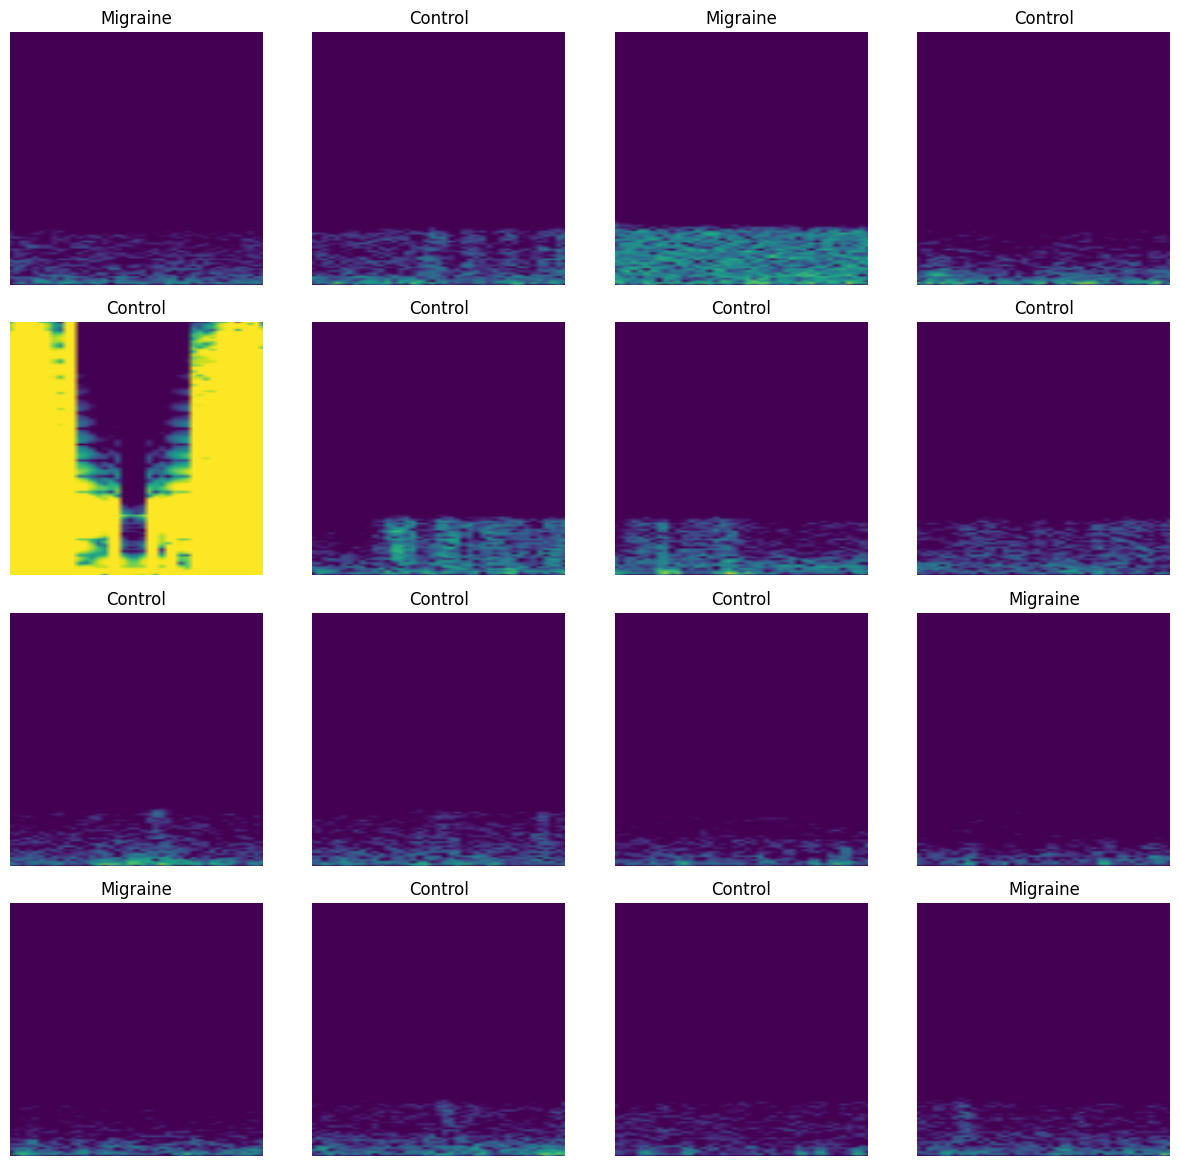

In [ ]:
plt.figure(figsize=(12, 12))
for batch_images, batch_labels in dataset.take(1):
    for i in range(16):
        ax = plt.subplot(4, 4, i + 1)
        plt.imshow(batch_images[i].numpy().astype("uint8"))
        plt.title(class_names[batch_labels[i]])
        plt.tight_layout()
        plt.axis("off")

plt.show()


# Splitting Dataset into Training, Validation, and Testing

In [ ]:
TRAIN_SIZE, TESTING_SIZE = 0.6, 0.4

In [ ]:
train_batch = int(len(dataset) * TRAIN_SIZE)
train_ds = dataset.take(train_batch).cache().prefetch(buffer_size=tf.data.AUTOTUNE)

In [ ]:
test_batch = int(len(dataset) * TESTING_SIZE)
test_ds = dataset.skip(train_batch).take(test_batch).cache().prefetch(buffer_size=tf.data.AUTOTUNE)

# Building Model

## Resizing and Normalization Layer

In [ ]:
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    layers.Rescaling(1./255),
])

## Model Architecture

In [ ]:
input_shape = (IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = len(class_names)
inputs = Input(shape=input_shape)

base_model = tf.keras.applications.ResNet50(
    include_top=False,
    weights='imagenet',
    input_tensor=inputs,
    pooling='avg'
)

base_model.trainable = False

x = base_model.output
x = Dense(units=128, activation='relu')(x)
outputs = Dense(n_classes, activation='softmax')(x)

model = Model(inputs=inputs, outputs=outputs)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,850,242 (90.98 MB)

 Trainable params: 262,530 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

We use `adam` Optimizer, `SparseCategoricalCrossentropy` for losses, `accuracy` as a metric

In [ ]:
model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics = ['accuracy']
)

Creating a checkpoint to save the model with the best score.

In [ ]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(filepath=model_path)
]

## Training

In [ ]:
history = model.fit(
    train_ds,
    batch_size = BATCH_SIZE,
    validation_data = test_ds,
    verbose = 1,
    epochs = EPOCHS,
    # epochs = 1,
    callbacks = callback
)

Epoch 1/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 41s 6s/step - accuracy: 0.3594 - loss: 1.1046 - val_accuracy: 0.4062 - val_loss: 0.7717
Epoch 2/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 358ms/step - accuracy: 0.4844 - loss: 0.7066 - val_accuracy: 0.6562 - val_loss: 0.7011
Epoch 3/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 434ms/step - accuracy: 0.6406 - loss: 0.7189 - val_accuracy: 0.6562 - val_loss: 0.7415
Epoch 4/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 527ms/step - accuracy: 0.6406 - loss: 0.7190 - val_accuracy: 0.6562 - val_loss: 0.7009
Epoch 5/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 473ms/step - accuracy: 0.6719 - loss: 0.6560 - val_accuracy: 0.6250 - val_loss: 0.6520
Epoch 6/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 361ms/step - accuracy: 0.6562 - loss: 0.6158 - val_accuracy: 0.6875 - val_loss: 0.6491
Epoch 7/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 343ms/step - accuracy: 0.6875 - loss: 0.6139 - val_accuracy: 0.6562 - val_loss: 0.6511
Epoch 8/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 325ms/step - accuracy: 0.6562 - loss: 0.6028 - val_accuracy: 0.6875 - val

## Loading Model

In [ ]:
model = load_model(model_path)

In [ ]:
# os.makedirs(drive_model_dir, exist_ok=True)
# shutil.copy(model_path, os.path.join(drive_model_dir, model_path))
# print(f"Model saved to: {os.path.join(drive_model_dir, model_path)}")

## Evaluation

### Predict

In [ ]:
all_predictions = []
all_probs = []
all_labels = []
for images, labels in test_ds:
    predictions = model.predict(images)
    all_probs.extend(predictions)
    predicted_classes = np.argmax(predictions, axis=1)
    all_predictions.extend(predicted_classes)
    all_labels.extend(labels.numpy())

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step


### Metrices

In [ ]:
accuracy = accuracy_score(all_labels, all_predictions)
f1 = f1_score(all_labels, all_predictions, average='weighted')
recall = recall_score(all_labels, all_predictions, average='weighted')
precision = precision_score(all_labels, all_predictions, average='weighted')
mcc = matthews_corrcoef(all_labels, all_predictions)

print("Accuracy: ", accuracy)
print("F1 Score: ", f1)
print("Recall: ", recall)
print("Precision: ", precision)
print("MCC: ", mcc)


Accuracy:  0.875
F1 Score:  0.8770833333333334
Recall:  0.875
Precision:  0.8861336032388665
MCC:  0.7410010097502685


### ROC AUC Cruve

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

def plot_multiclass_roc(y_true, y_probs, class_names=None):
    y_true = np.array(y_true)
    n_classes = y_probs.shape[1]

    if n_classes == 2:
        y_bin = np.zeros((len(y_true), 2))
        y_bin[np.arange(len(y_true)), y_true] = 1
    else:
        y_bin = label_binarize(y_true, classes=range(n_classes))

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], y_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    fig, ax = plt.subplots(figsize=(6, 4))

    for i in range(n_classes):
        label = f"Class {i}" if class_names is None else class_names[i]
        ax.plot(fpr[i], tpr[i], lw=2,
                label=f'{label} (AUC = {roc_auc[i]:.4f})')

    ax.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Classifier')
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title('ROC AUC Curve')
    ax.grid(True)

    ax.legend(loc='lower right', fontsize='small')

    plt.tight_layout()
    plt.savefig('ROC AUC Curve.png', dpi=600)
    plt.show()

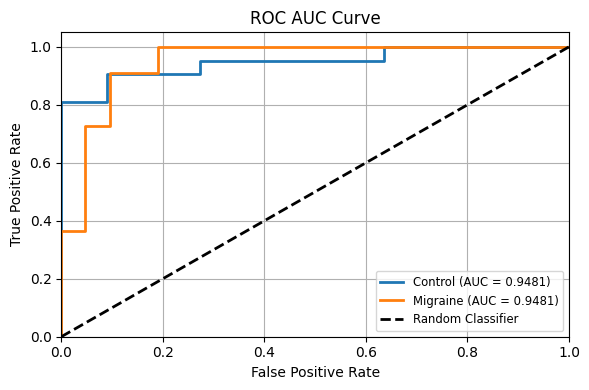

In [ ]:
plot_multiclass_roc(all_labels, np.array(all_probs), class_names=class_names)

### Confusion Matrix

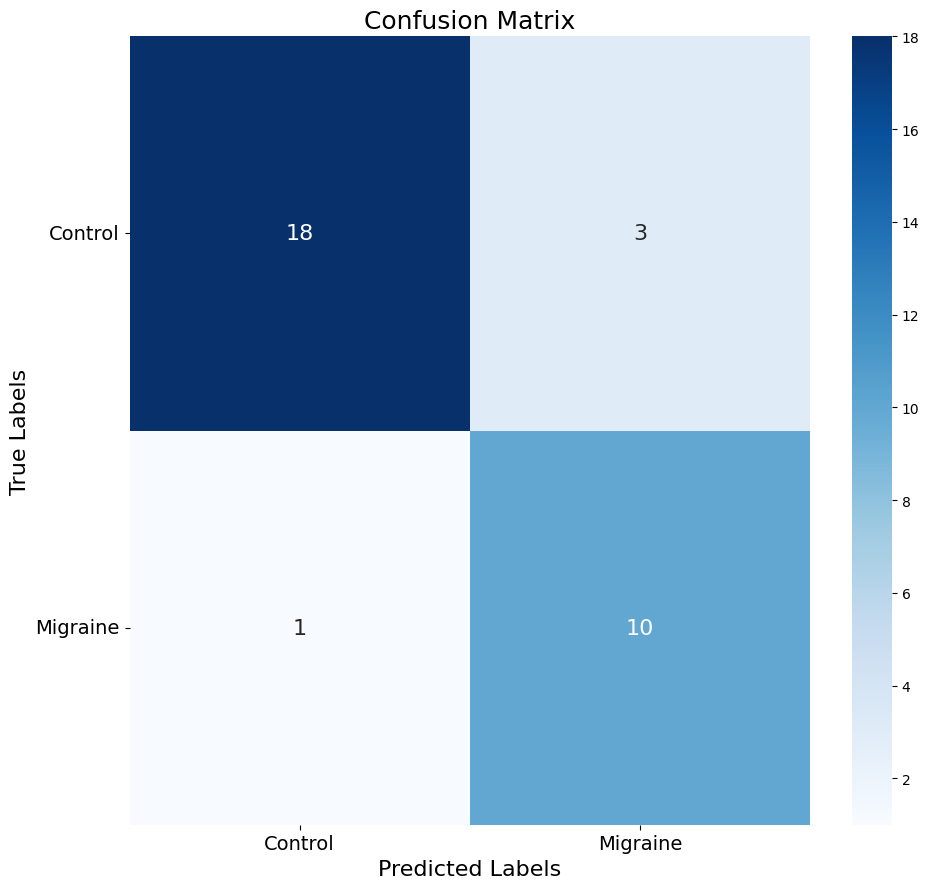

In [ ]:
conf_matrix = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(10, 9))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 16}
)
plt.xlabel("Predicted Labels", fontsize=16)
plt.ylabel("True Labels", fontsize=16)
plt.title("Confusion Matrix", fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14, rotation=0)
plt.tight_layout()
plt.savefig("Efficientnet CM.png", dpi = 600)
plt.show()

# Plotting the Accuracy and Loss Curves

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

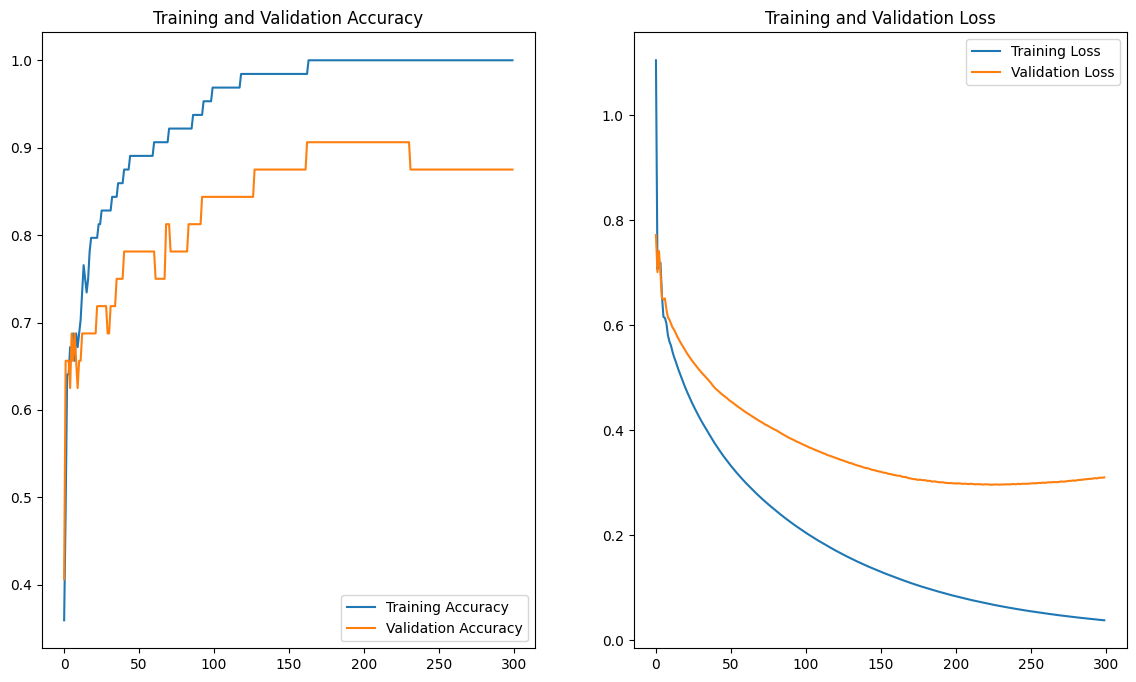

In [ ]:
plt.figure(figsize=(14, 8))
plt.subplot(1, 2, 1)
plt.plot(range(EPOCHS), acc, label='Training Accuracy')
plt.plot(range(EPOCHS), val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(range(EPOCHS), loss, label='Training Loss')
plt.plot(range(EPOCHS), val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

# Inference



## Inference Function

In [ ]:
def predict(model, image):
    img_array = tf.keras.preprocessing.image.img_to_array(image.numpy())
    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array)

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

## Running Inference on Sample Images

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


<Figure size 640x480 with 0 Axes>

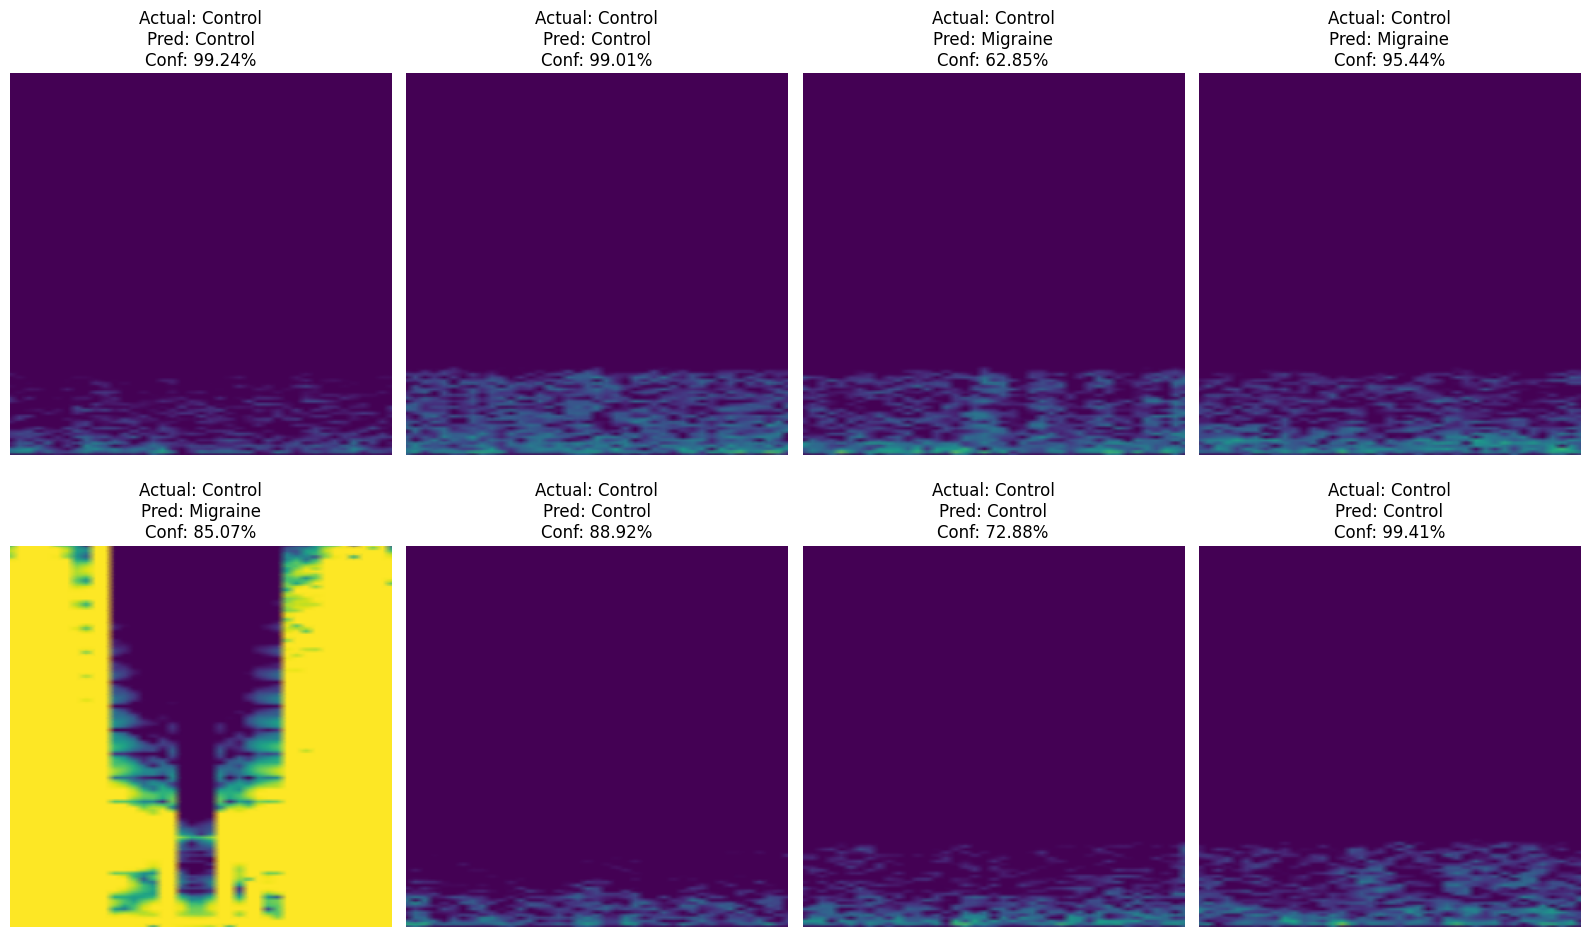

In [ ]:
plt.clf()
plt.figure(figsize=(16, 10))
image_count = 0

for images, labels in test_ds.take(3):
    for i in range(min(8, len(images))):
        ax = plt.subplot(2, 4, i + 1)
        ax.imshow(images[i].numpy().astype("uint8"))

        predicted_class, confidence = predict(model, images[i])
        actual_class = class_names[labels[i]]

        ax.set_title(f"Actual: {actual_class}\nPred: {predicted_class}\nConf: {confidence:.2f}%")
        ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
from google.colab import runtime
runtime.unassign()